In [1]:
from pathlib import Path
BASE = Path("/home/lka/HYBRID_SARIMA")
print(BASE.exists(), BASE)

#Import the file to read it
import pandas as pd
disocupati_trimestral = pd.read_csv(BASE / 'data.csv', 
                       index_col='Period', 
                       parse_dates=True)
print(disocupati_trimestral)

True /home/lka/HYBRID_SARIMA
             15-34 M    15-34 F   35-49 M   35-49 F   50-74 M   50-74 F  \
Period                                                                    
2004-Q1    11.720628  17.198032  4.283283  8.776062  4.004764  5.376203   
2004-Q2    11.410664  16.187372  3.654493  7.196378  3.636536  4.515018   
2004-Q3    10.041510  15.682014  3.520125  6.945425  3.394804  3.976243   
2004-Q4    11.918557  17.227696  4.020448  7.582207  3.604743  3.583677   
2005-Q1    12.334781  16.852636  4.316241  7.577546  3.440298  4.204936   
...              ...        ...       ...       ...       ...       ...   
2025-Q2    11.341464  13.635416  5.106017  7.025122  3.776334  3.889283   
2025-Q3     9.628072  11.355385  4.656108  6.239399  3.108541  3.482718   
2025-Q4    10.903735  10.928362  3.989899  5.704370  3.250742  3.129547   
2026-Q1     9.534584  10.900056  4.316380  5.611548  2.984988  3.392216   
2026-Q2    10.244865  11.855438  5.044973  6.388627  3.268385  3.460483

/tmp/ipykernel_16332/3099411105.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  disocupati_trimestral = pd.read_csv(BASE / 'data.csv',


In [2]:
#Dividir el dataset en training, validation y test
series = [
    '15-34 M', '15-34 F',
    '35-49 M', '35-49 F',
    '50-74 M', '50-74 F',
    'Global_Rate'
]

# Ordenar cronológicamente
df = disocupati_trimestral.sort_index()

# División 70% Train, 15% Validation, 15% Test
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = df[series].iloc[:train_end].copy()
val = df[series].iloc[train_end:val_end].copy()
test = df[series].iloc[val_end:].copy()

# Mostrar resultados para cada serie
#for serie in series:
#    print(f"\nSerie: {serie}")
#    print(f"Train: {len(train[serie])} observaciones")
#    print(f"Validation: {len(val[serie])} observaciones")
#    print(f"Test: {len(test[serie])} observaciones")

print(train)
print(val)
print(test)


             15-34 M    15-34 F   35-49 M    35-49 F   50-74 M   50-74 F  \
Period                                                                     
2004-Q1    11.720628  17.198032  4.283283   8.776062  4.004764  5.376203   
2004-Q2    11.410664  16.187372  3.654493   7.196378  3.636536  4.515018   
2004-Q3    10.041510  15.682014  3.520125   6.945425  3.394804  3.976243   
2004-Q4    11.918557  17.227696  4.020448   7.582207  3.604743  3.583677   
2005-Q1    12.334781  16.852636  4.316241   7.577546  3.440298  4.204936   
...              ...        ...       ...        ...       ...       ...   
2018-Q2    17.908050  21.321705  7.759217  10.435680  6.683032  6.283515   
2018-Q3    16.802144  19.343542  6.191831   9.120602  5.538136  5.299045   
2018-Q4    19.322895  22.132355  7.396393  10.673055  6.327076  6.189145   
2019-Q1    19.163606  21.713279  8.111591  11.250865  6.697788  6.034775   
2019-Q2    17.128382  19.347371  7.161324   9.818228  5.738406  5.356958   

           

In [3]:

sarima_best_params={
    "15-34 M":{"order":(0,1,0),"seasonal_order":(0,1,1,4)},
    "15-34 F":{"order":(0,1,0),"seasonal_order":(0,1,1,4)},
    "35-49 M":{"order":(0,1,0),"seasonal_order":(1,1,2,4)},
    "35-49 F":{"order":(0,1,0),"seasonal_order":(0,1,1,4)},
    "50-74 M":{"order":(2,1,1),"seasonal_order":(0,1,1,4)},
    "50-74 F":{"order":(2,1,0),"seasonal_order":(0,1,1,4)},
    "Global_Rate":{"order":(0,1,0),"seasonal_order":(0,1,1,4)}
}


In [ ]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from itertools import product
from pathlib import Path
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

architectures=[(32,),(64,),(128,),(32,32),(64,32),(64,64),(128,32),(128,64),(128,128)]
grid=list(product(architectures,[0.01,0.001],[4,6,8],[100],[16,32],[0.0,0.1,0.3]))

class GRU(nn.Module):
    def __init__(self,neurons,dropout):
        super().__init__()
        self.layers=nn.ModuleList()
        size=1
        for n in neurons:
            self.layers.append(nn.GRU(size,n,batch_first=True))
            size=n
        self.drop=nn.Dropout(dropout)
        self.fc=nn.Linear(size,1)

    def forward(self, x):                            # función forward de la GRU
            for i, layer in enumerate(self.layers):
                x, _ = layer(x)
                if i == 0:
                    x = self.drop(x)                      # aplicar dropout solo a la primera capa GRU
            return self.fc(x[:, -1, :])

def sequences(data,window,start,end):
    X=np.array([data[i-window:i] for i in range(start,end)],dtype=np.float32)
    y=np.array(data[start:end],dtype=np.float32)
    X=torch.tensor(X.reshape(-1,window,1),device=device)
    y=torch.tensor(y.reshape(-1,1),device=device)
    return X,y

def fit_gru(res_train,res_val,params,final=False,best_epoch=None):
    neurons,lr,window,epochs,batch,dropout=params
    torch.manual_seed(42)
    scaler=MinMaxScaler()
    scaler.fit(res_train.reshape(-1,1))
    residuals=np.concatenate([res_train,res_val])
    z=scaler.transform(residuals.reshape(-1,1)).ravel()
    split=len(res_train)
    end=len(z) if final else split
    X,y=sequences(z,window,window,end)
    model=GRU(neurons,dropout).to(device)
    optimizer=torch.optim.Adam(model.parameters(),lr=lr)
    criterion=nn.MSELoss()
    best=np.inf
    best_epoch_found=0
    best_val_pred=None
    wait=0
    total_epochs=best_epoch if final else epochs

    for epoch in range(total_epochs):
        model.train()
        idx=torch.randperm(len(X),device=device)

        for ids in idx.split(batch):
            optimizer.zero_grad()
            loss=criterion(model(X[ids]),y[ids])
            loss.backward()
            optimizer.step()

        if not final:
            model.eval()
            with torch.no_grad():
                Xv,yv=sequences(z,window,split,len(z))
                pred=model(Xv).cpu().numpy()
                actual=yv.cpu().numpy()

            pred=scaler.inverse_transform(pred)
            actual=scaler.inverse_transform(actual)
            mse=mean_squared_error(actual,pred)

            if mse<best-1e-10:
                best=mse
                best_epoch_found=epoch+1
                wait=0
                best_val_pred=pred.ravel().copy()
            else:
                wait+=1

            if wait>=15:
                break

    if final:
        return model,scaler

    return best,best_epoch_found,epoch+1, best_val_pred

grid_results=[]
results=[]
best_params={}
hybrid_predictions={}

for col,params in sarima_best_params.items():
    y_train=train[col]
    y_val=val[col]
    y_train_val=pd.concat([y_train,y_val])
    y_test=test[col]

    sarima_train=SARIMAX(
        y_train.reset_index(drop=True),
        order=params["order"],
        seasonal_order=params["seasonal_order"],
        enforce_stationarity=True,
        enforce_invertibility=True
    ).fit(disp=False)

    burn=sarima_train.loglikelihood_burn
    res_train=sarima_train.resid.to_numpy()[burn:]
    sarima_val=np.asarray(sarima_train.forecast(steps=len(y_val)))
    res_val=y_val.to_numpy()-sarima_val

    best_mse=np.inf
    best_config=None
    best_epoch=0

    for config in grid:
        mse,epoch,trained,pred_res=fit_gru(res_train,res_val,config)
        neurons,lr,window,epochs,batch,dropout=config
        
        # Métricas del conjunto de VALIDACIÓN
        real_val=y_val.to_numpy()
        hybrid_val=sarima_val+pred_res
        
        mae=mean_absolute_error(real_val,hybrid_val)
        rmse=np.sqrt(mse)
        
        mask=real_val!=0
        mape=np.mean(
            np.abs((real_val[mask]-hybrid_val[mask])/real_val[mask])
        )*100 if mask.any() else np.nan
        
        values=y_train.to_numpy()
        scale=np.mean(np.abs(values[4:]-values[:-4]))
        mase=mae/scale if scale>0 else np.nan
        
        r2=r2_score(real_val,hybrid_val)
        
        grid_results.append([
            col,len(neurons),str(neurons),lr,window,
            epochs,epoch,trained,batch,dropout,
            mse,mae,rmse,mape,mase,r2
        ])

        if mse<best_mse:
            best_mse=mse
            best_config=config
            best_epoch=epoch

    best_params[col]={
        "params":best_config,
        "best_epoch":best_epoch,
        "MSE_Validation":best_mse
    }

    sarima=SARIMAX(
        y_train_val.reset_index(drop=True),
        order=params["order"],
        seasonal_order=params["seasonal_order"],
        enforce_stationarity=True,
        enforce_invertibility=True
    ).fit(disp=False)

    residuals=sarima.resid.to_numpy()[sarima.loglikelihood_burn:]

    gru,scaler=fit_gru(
        residuals,
        np.array([]),
        best_config,
        final=True,
        best_epoch=best_epoch
    )

    sarima_pred=np.asarray(sarima.forecast(steps=len(y_test)))
    history=list(residuals)
    gru_pred=[]

    for i in range(len(y_test)):
        window=best_config[2]
        x=np.array(history[-window:]).reshape(-1,1)
        x=scaler.transform(x)
        x=torch.tensor(x.reshape(1,window,1),dtype=torch.float32,device=device)

        gru.eval()
        with torch.no_grad():
            pred=gru(x).cpu().numpy()

        pred=scaler.inverse_transform(pred)[0,0]
        gru_pred.append(pred)
        history.append(float(y_test.iloc[i])-sarima_pred[i])

    gru_pred=np.array(gru_pred)
    hybrid_pred=sarima_pred+gru_pred
    real=y_test.to_numpy()

    mae=mean_absolute_error(real,hybrid_pred)
    mse=mean_squared_error(real,hybrid_pred)
    rmse=np.sqrt(mse)
    mask=real!=0
    mape=np.mean(np.abs((real[mask]-hybrid_pred[mask])/real[mask]))*100 if mask.any() else np.nan

    values=y_train_val.to_numpy()
    scale=np.mean(np.abs(values[4:]-values[:-4]))
    mase=mae/scale if scale>0 else np.nan
    r2=r2_score(real,hybrid_pred)

    results.append([col,mae,mse,rmse,mape,mase,r2])

    hybrid_predictions[col]=pd.DataFrame({
        "Observed":real,
        "SARIMA":sarima_pred,
        "GRU_Residual":gru_pred,
        "Hybrid":hybrid_pred
    },index=y_test.index)

    print(col,"Validation MSE:",round(best_mse,4),"Test MSE:",round(mse,4))

grid_df=pd.DataFrame(grid_results,columns=[
    "Serie","Layers","Neurons","Learning_Rate","Window",
    "Epochs","Best_Epoch","Epochs_Trained","Batch_Size",
    "Dropout","MSE","MAE","RMSE","MAPE","MASE","R2"
])

grid_df=grid_df.sort_values(["Serie","MSE"]).reset_index(drop=True)
grid_df["Rank"]=grid_df.groupby("Serie").cumcount()+1
top10=grid_df[grid_df["Rank"]<=10]

results_df=pd.DataFrame(results,columns=[
    "Serie","MAE","MSE","RMSE","MAPE","MASE","R2"
])

output=Path("results/SARIMA_GRU_Sequential")
output.mkdir(parents=True,exist_ok=True)

top10.to_csv(output/"top10_sarima_gru.csv",index=False)
results_df.to_csv(output/"sarima_gru_test.csv",index=False)

for col,pred in hybrid_predictions.items():
    pred.to_csv(output/f"pred_{col.replace(' ','_')}.csv")

print(results_df.round(4))    
print(best_params)  

  

In [ ]:
gru_best_params = {
    "15-34 M": {"neurons": (128,), "lr": 0.01, "window": 4, "epochs": 3, "batch": 32, "dropout": 0.0},
    "15-34 F": {"neurons": (128, 64), "lr": 0.01, "window": 8, "epochs": 97, "batch": 16, "dropout": 0.3},
    "35-49 M": {"neurons": (128, 64), "lr": 0.01, "window": 4, "epochs": 88, "batch": 16, "dropout": 0.0},
    "35-49 F": {"neurons": (128,), "lr": 0.001, "window": 4, "epochs": 5, "batch": 32, "dropout": 0.3},
    "50-74 M": {"neurons": (32,), "lr": 0.01, "window": 8, "epochs": 21, "batch": 16, "dropout": 0.0},
    "50-74 F": {"neurons": (128, 128), "lr": 0.01, "window": 8, "epochs": 59, "batch": 32, "dropout": 0.3},
    "Global_Rate": {"neurons": (128, 128), "lr": 0.01, "window": 8, "epochs": 52, "batch": 16, "dropout": 0.1}
}

In [ ]:
# Academic style
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", font_scale=1.3)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "savefig.bbox": "tight"
})

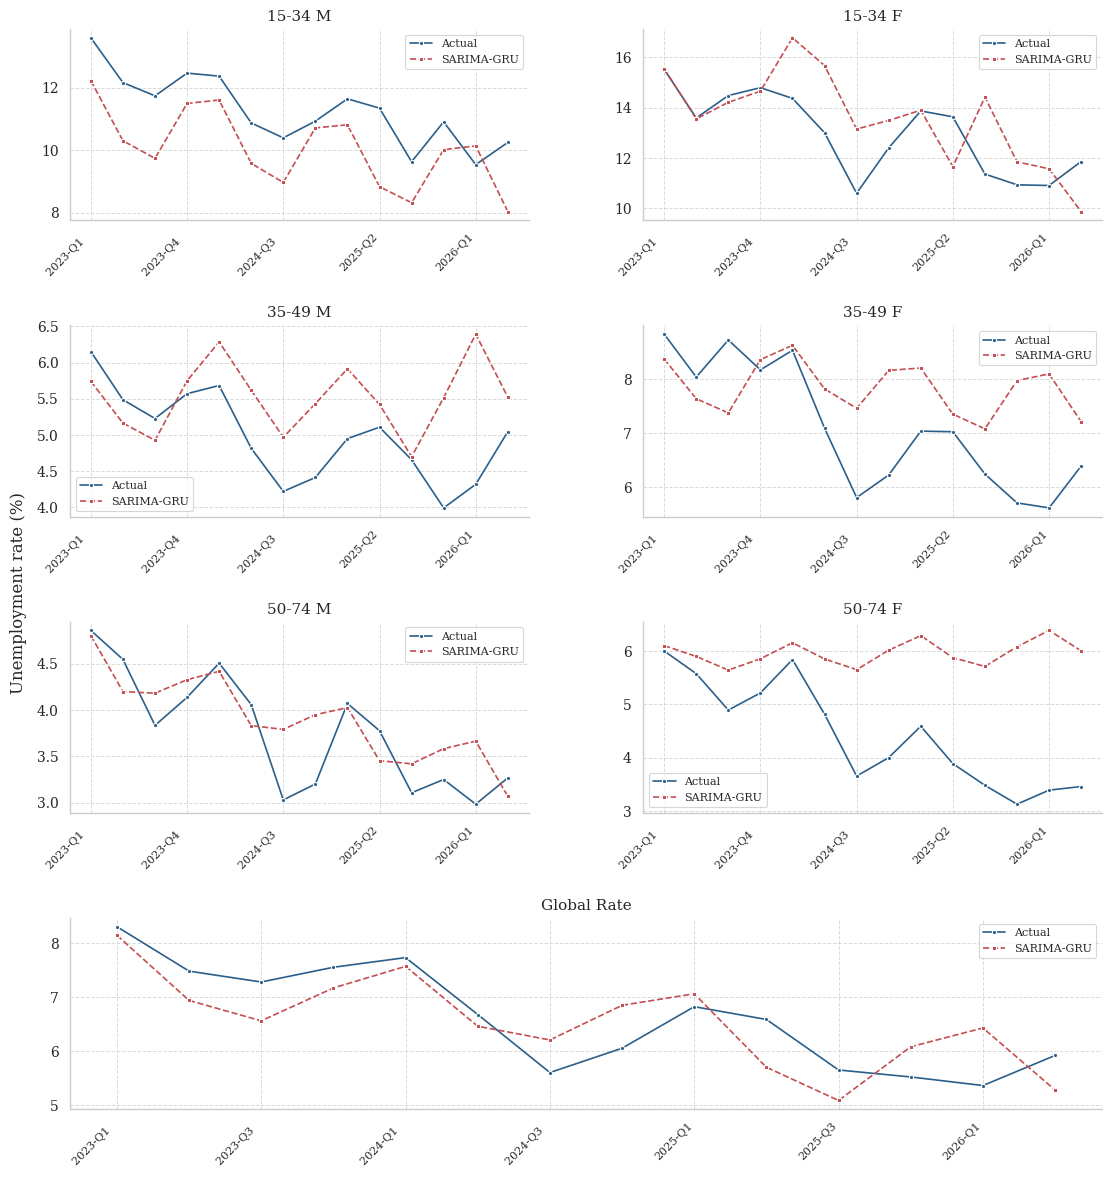

In [ ]:
fig = plt.figure(figsize=(12,12))
gs = fig.add_gridspec(4,2,hspace=0.55,wspace=0.25)
axes = [fig.add_subplot(gs[i//2,i%2]) for i in range(6)]
axes.append(fig.add_subplot(gs[3,:]))

for i,(ax,col) in enumerate(zip(axes,series)):
    #leer de los archivos guardados en la carpeta SARIMA_GRU_sequential
    #df = hybrid_predictions[col]
    df = pd.read_csv(BASE /"results"/"SARIMA_GRU_Sequential" / f"pred_{col.replace(' ', '_')}.csv", index_col=0)
    x = df.index

    sns.lineplot(x=x,y=df["Observed"],ax=ax,color="#2B5F8A",
                 marker="o",markersize=3,linewidth=1.2,label="Actual")

    sns.lineplot(x=x,y=df["Hybrid"],ax=ax,color="#C44E52",
                 marker="s",markersize=3,linewidth=1.2,
                 linestyle="--",label="SARIMA-GRU")

    ax.set_title(col.replace("_"," "),fontsize=11)
    ax.set(xlabel="",ylabel="")
    ticks = x[::2] if i==6 else x[::3]
    ax.set_xticks(ticks)
    ax.set_xticklabels(ticks,rotation=45,ha="right",fontsize=8)
    ax.grid(True,linestyle="--",linewidth=0.7,alpha=0.7)
    ax.legend(fontsize=8)
    sns.despine(ax=ax)

fig.supylabel("Unemployment rate (%)",fontsize=12,x=0.07)
fig.subplots_adjust(left=0.12,right=0.98,top=0.97,bottom=0.07)

IMG = BASE / "IMG"
IMG.mkdir(parents=True,exist_ok=True)
fig.savefig(IMG/"sarima_gru_sequential_forecast_test.pdf",bbox_inches="tight")
plt.show()

In [ ]:
rng = np.random.default_rng(42)
B, block_size = 2000, 4
ci_results = []

for col in series:
    df = pd.read_csv(BASE/"results"/"SARIMA_GRU_Sequential"/f"pred_{col.replace(' ','_')}.csv")

    real = df["Observed"].to_numpy()
    pred = df["Hybrid"].to_numpy()
    n = len(real)

    if n < block_size:
        raise ValueError(f"{col}: test demasiado corto")

    def calc(y, p):
        e = y-p
        mask = y != 0
        return {
            "MSE": np.mean(e**2),
            "RMSE": np.sqrt(np.mean(e**2)),
            "MAE": np.mean(np.abs(e)),
            "MAPE": np.mean(np.abs(e[mask]/y[mask]))*100 if mask.any() else np.nan
        }

    point = calc(real, pred)
    boot = {m: [] for m in point}

    for _ in range(B):
        starts = rng.integers(0,n-block_size+1,size=int(np.ceil(n/block_size)))
        idx = np.concatenate([np.arange(s,s+block_size) for s in starts])[:n]

        for m,v in calc(real[idx],pred[idx]).items():
            boot[m].append(v)

    row = {"Serie": col}
    for m in point:
        lo,hi = np.nanpercentile(boot[m],[2.5,97.5])
        row[m] = round(point[m],4)
        row[f"{m} IC 95%"] = f"[{lo:.4f}, {hi:.4f}]"

    ci_results.append(row)

sarima_gru_ci_df = pd.DataFrame(ci_results)
sarima_gru_ci_df.to_csv(BASE/"results"/"SARIMA_GRU_Sequential"/"sarima_gru_IC_test.csv",index=False)
display(sarima_gru_ci_df)

,Serie,MSE,MSE IC 95%,RMSE,RMSE IC 95%,MAE,MAE IC 95%,MAPE,MAPE IC 95%
0,15-34 M,2.1000,"[1.3285, 2.5222]",1.4491,"[1.1526, 1.5881]",1.3042,"[1.0329, 1.4488]",11.6400,"[9.2700, 12.8985]"
1,15-34 F,2.8126,"[1.6791, 4.5570]",1.6771,"[1.2958, 2.1347]",1.2761,"[0.7932, 1.9127]",10.4737,"[6.1105, 15.7122]"
2,35-49 M,0.7796,"[0.2449, 1.2419]",0.8829,"[0.4949, 1.1144]",0.6997,"[0.4147, 0.8923]",15.1562,"[8.2137, 20.3877]"
3,35-49 F,1.6789,"[0.7002, 2.5004]",1.2957,"[0.8368, 1.5813]",1.0534,"[0.6373, 1.3840]",16.4975,"[8.6275, 23.2772]"
4,50-74 M,0.1634,"[0.0731, 0.2729]",0.4043,"[0.2703, 0.5224]",0.3321,"[0.2454, 0.4405]",9.7908,"[6.3993, 13.4171]"
5,50-74 F,3.2956,"[0.8072, 5.3374]",1.8154,"[0.8985, 2.3103]",1.5395,"[0.7349, 2.2530]",41.0302,"[15.7128, 62.6871]"
6,Global_Rate,0.3614,"[0.2052, 0.4971]",0.6011,"[0.4530, 0.7051]",0.5376,"[0.3976, 0.6611]",8.6430,"[5.8415, 11.2916]"
